In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from IPython.display import clear_output

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F
from torch.utils.data import Subset
import numpy as np
import pandas as pd
import copy
from torch.utils.data import ConcatDataset
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader
import os
from IPython.display import clear_output

In [2]:
class BinaryClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.GroupNorm(32, 64), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GroupNorm(32, 128), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.GroupNorm(32, 256), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.GroupNorm(32, 512), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128)
        )
        
        self.fc = nn.Linear(512 + 128, 2)

    def forward(self, x, t):
        img_feats = self.features(x)
        
        if t.dim() == 1:
            t = t.unsqueeze(-1).float()
            
        time_feats = self.time_mlp(t)
        
        combined = torch.cat([img_feats, time_feats], dim=1)
        return self.fc(combined)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class uNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biCls = BinaryClassifier().to(device)
cls = Classifier().to(device)
model = uNet().to(device)

biCls.load_state_dict(torch.load("8_binary_clsf.pth", map_location=device))
cls.load_state_dict(torch.load("mnist_cnn_wei.pth", map_location=device))
model.load_state_dict(torch.load("uncond_diff_wei.pth", map_location=device))

<All keys matched successfully>

In [4]:
img_size = 28
batch_size = 128
epochs = 100
timesteps = 500
img_size = 28

beta = torch.linspace(1e-4, 0.02, timesteps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

In [7]:
n_samples = 1
s = 0
final = []

final_outputs = []

with torch.no_grad():
    xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
    
    for i in reversed(range(timesteps)):
        # print(i)
        t = torch.tensor([i] * n_samples, device=device)
        
        eps_pred = model(xt, t.float() / timesteps)
        
        alpha_t = alpha[i]
        alpha_bar_t = alpha_bar[i]
        beta_t = beta[i]

        mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)

        with torch.enable_grad():
            dre_xt = xt.detach().clone().requires_grad_(True)
            
            logits = biCls(dre_xt, t) 
            log_probs = F.log_softmax(logits, dim=1)
            
            r = log_probs[:, 1] - log_probs[:, 0]
            
            guide_score = torch.autograd.grad(
                outputs=r.sum(),
                inputs=dre_xt
            )[0]
            
        mean = mean + s * beta_t * guide_score
        
        if i > 0:
            noise = torch.randn_like(xt)
            xt = mean + torch.sqrt(beta_t) * noise
        else:
            xt = mean

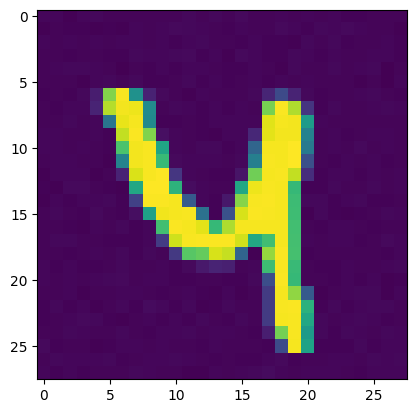

In [9]:
plt.imshow(xt.cpu().detach()[0, 0])